In [78]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
import torch
import scipy
import splines
import pyclipr

In [98]:
MODELS = ["curvature_close_w1_s1", "baseline_w0_s2"]
trajectories = [torch.load(f"results/trajectory_{model}.pt", weights_only=False) for model in MODELS]

In [99]:
centerline_steps = [[6, 0], [6.1115756, -1.43028975], [5.95127964, -2.83081627], [5.58174753, -4.1653614], [4.83527899, -5.25710821], [3.88531017, -6.10326338], [3.00019217, -7.04225159], [1.93370247, -7.65328074], [0.80612874, -7.61801624], [-0.28149271, -8.16725254], [-1.38312149, -8.01338196], [-1.88635778, -7.09106827], [-2.53355742, -6.26302385], [-3.10132265, -5.37949467], [-2.54613733, -4.37741375], [-1.50412416, -3.70642257], [-0.609011054, -2.89762616], [-0.250633955, -1.83911538], [0.116319776, -0.782353401], [0.406481028, 0.287876964], [0.047311902, 1.27935815], [-0.0593253374, 2.34325171], [0.241416693, 3.41191721], [0.657000244, 4.45757437], [1.59622145, 5.22951174], [2.87048268, 5.53261852], [4.23373127, 5.24737978], [5.13541746, 4.09655666], [5.46117592, 2.68465495], [6.16075945, 1.4004246]]
centerline_spline = splines.CatmullRom(centerline_steps, endconditions='closed', alpha=0.5)
centerline = centerline_spline.evaluate(np.linspace(centerline_spline.grid[0], centerline_spline.grid[-1], 1000))
po = pyclipr.ClipperOffset()
po.addPath(centerline, pyclipr.JoinType.Miter, pyclipr.EndType.Joined)
clip_outset, clip_inset = po.execute(1)

In [100]:
[t["agents", "progress"].mean() for t in trajectories]

[tensor(0.1850), tensor(0.1945)]

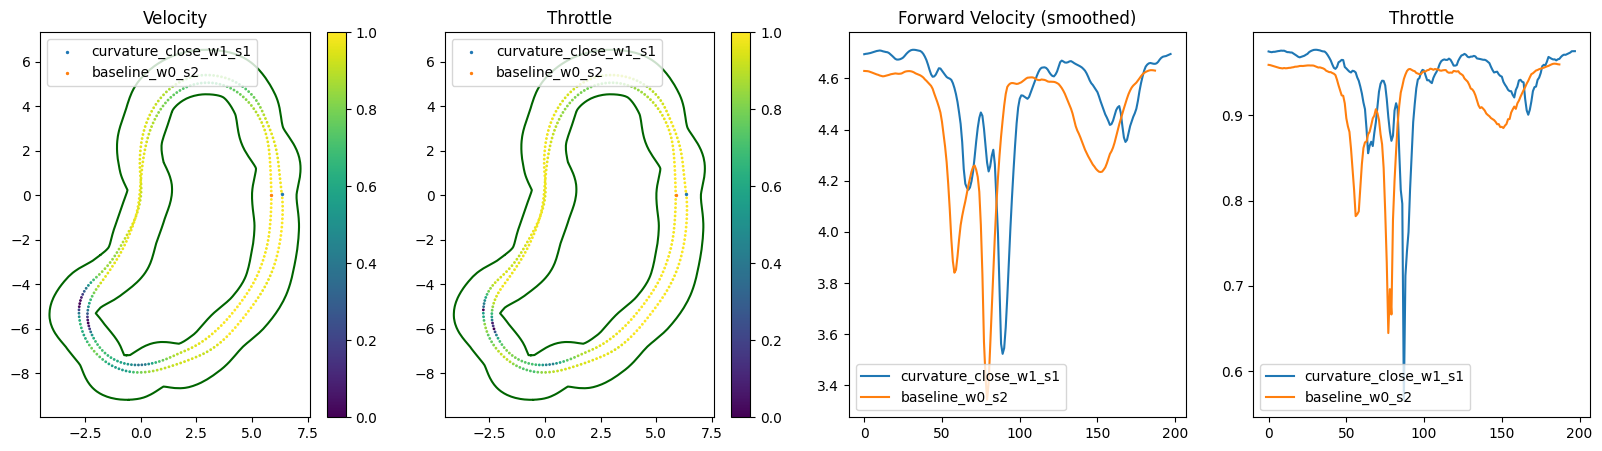

In [110]:
fig, axs = plt.subplots(1, 4,figsize=(20, 5))

axs[0].plot(clip_outset[:, 0], clip_outset[:, 1], color="darkgreen")
axs[0].plot(clip_inset[:, 0], clip_inset[:, 1], color="darkgreen")
axs[1].plot(clip_outset[:, 0], clip_outset[:, 1], color="darkgreen")
axs[1].plot(clip_inset[:, 0], clip_inset[:, 1], color="darkgreen")

lap_no = 2

for episode, model, idx in zip(trajectories, MODELS, range(len(MODELS))):
    x = episode["agents", "x"].squeeze(-1)
    z = episode["agents", "z"].squeeze(-1)

    start_x, start_z = x[0], z[0]
    dist_from_start = ((x - start_x) ** 2 + (z - start_z) ** 2).numpy()

    min_indices = scipy.signal.argrelextrema(dist_from_start, np.less)[0]
    min_indices = np.concatenate([[0], min_indices, [len(dist_from_start) - 1]])
    min_indices = min_indices[dist_from_start[min_indices] < 0.5]

    lap_shown = episode[min_indices[lap_no]:min_indices[lap_no + 1]]
    
    axs[0].scatter(
        lap_shown["agents", "x"], 
        lap_shown["agents", "z"], 
        c=lap_shown["agents", "velocity_forward"],
        s=1)

    sc = axs[0].scatter(
            lap_shown["agents", "x"][0], 
            lap_shown["agents", "z"][0], 
            label=f"{model}",
            s=2
        )
    if idx == 0:
        plt.colorbar(sc)
    axs[0].legend(loc="upper left")

    axs[0].axis("equal")
    axs[0].set_title("Velocity")

    axs[1].scatter(
        lap_shown["agents", "x"], 
        lap_shown["agents", "z"], 
        c=lap_shown["agents", "throttle"],
        s=1)

    sc = axs[1].scatter(
            lap_shown["agents", "x"][0], 
            lap_shown["agents", "z"][0], 
            label=f"{model}",
            s=2
        )
    if idx == 0:
        plt.colorbar(sc)
    axs[1].legend(loc="upper left")

    axs[1].axis("equal")
    axs[1].set_title("Throttle")

    axs[2].plot(np.convolve(lap_shown["agents", "velocity_forward"].numpy().reshape(-1), np.ones(1)/1, mode="valid"), label=model)
    axs[2].set_title("Forward Velocity (smoothed)")
    axs[2].legend()

    axs[3].plot(lap_shown["agents", "throttle"].numpy().reshape(-1), label=model)
    axs[3].set_title("Throttle")
    axs[3].legend()
